# Comparing Linear and Nonlinear Causality

## 1. Linear dynamical system

The next value depends linearly on the previous values:

$$
X_t = 0.4X_{t-1} + a_{yx}Y_{t-1} + \epsilon_{x,t}
$$

and 
$$
Y_t = 0.3Y_{t-1} + a_{xy}X_{t-1} + \epsilon_{y,t}
$$
 
## 2. Nonlinear chaotic system

The dynamics include nonlinear interactions:

$$
X_t = r_x X_{t-1} - r_x X_{t-1}^2
      - \beta_{xy}X_{t-1}Y_{t-1}
$$
 
and
$$
Y_t = r_yY_{t-1} - r_yY_{t-1}^2
      - \beta_{yx}Y_{t-1}X_{t-1}
$$


In [1]:

import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests

# ============================================================
# Linear VAR system: validate Granger-causality detection
# ============================================================

T = 3000
BURN_IN = 500
MAX_LAG = 1
ALPHA = 0.05
NOISE_STD = 1.0
SEED = 42

rng = np.random.default_rng(SEED)


def generate_linear_series(a_xy, a_yx):
    """
    a_xy: X -> Y
    a_yx: Y -> X

    Stable linear system:
      X[t] = 0.4 X[t-1] + a_yx Y[t-1] + noise_x
      Y[t] = 0.3 Y[t-1] + a_xy X[t-1] + noise_y
    """
    n = T + BURN_IN
    X = np.zeros(n)
    Y = np.zeros(n)

    for t in range(1, n):
        eps_x, eps_y = rng.normal(0, NOISE_STD, size=2)

        X[t] = 0.4 * X[t-1] + a_yx * Y[t-1] + eps_x
        Y[t] = 0.3 * Y[t-1] + a_xy * X[t-1] + eps_y

    X = X[BURN_IN:]
    Y = Y[BURN_IN:]

    if not np.all(np.isfinite(X)) or not np.all(np.isfinite(Y)):
        raise ValueError("Simulation unstable: non-finite values detected.")

    return X, Y


def granger_pvalue(target, source, max_lag=MAX_LAG):
    """
    Test whether source Granger-causes target.
    Column order is [target, source].
    """
    df = pd.DataFrame({
        "target": target,
        "source": source
    })

    result = grangercausalitytests(
        df[["target", "source"]],
        maxlag=[max_lag]
    )

    # SSR F-test p-value
    return result[max_lag][0]["ssr_ftest"][1]


conditions = {
    "No coupling":         (0.0, 0.0),
    "Only X -> Y":         (0.5, 0.0),
    "Only Y -> X":         (0.0, 0.5),
    "Bidirectional":       (0.5, 0.5),
}

for condition, (a_xy, a_yx) in conditions.items():

    X, Y = generate_linear_series(a_xy, a_yx)

    print("Unique X values:", len(np.unique(X)))
    print("Unique Y values:", len(np.unique(Y)))
    print("First X values:", X[:5])
    print("First Y values:", Y[:5])

    
    # Test Y -> X and X -> Y separately
    p_y_to_x = granger_pvalue(target=X, source=Y)
    p_x_to_y = granger_pvalue(target=Y, source=X)

    # Rows = targets; columns = sources
    EC = np.zeros((2, 2), dtype=int)
    EC[0, 1] = int(p_y_to_x < ALPHA)  # Y -> X
    EC[1, 0] = int(p_x_to_y < ALPHA)  # X -> Y

    EC_df = pd.DataFrame(
        EC,
        index=["X", "Y"],
        columns=["X", "Y"]
    )

    print(f"\n{'=' * 45}")
    print(f"Condition: {condition}")
    print(f"Ground truth X -> Y: {int(a_xy != 0)}")
    print(f"Ground truth Y -> X: {int(a_yx != 0)}")
    print(f"p-value Y -> X: {p_y_to_x:.6g}")
    print(f"p-value X -> Y: {p_x_to_y:.6g}")
    print("\nBinary effective connectivity:")
    print(EC_df)


Unique X values: 3000
Unique Y values: 3000
First X values: [ 0.5489789   0.16030891 -0.3503495  -0.13714651  0.61522064]
First Y values: [ 0.93855919 -0.44771918  0.49959462  0.49008836 -0.22781495]

Condition: No coupling
Ground truth X -> Y: 0
Ground truth Y -> X: 0
p-value Y -> X: 0.997819
p-value X -> Y: 0.939721

Binary effective connectivity:
   X  Y
X  0  0
Y  0  0
Unique X values: 3000
Unique Y values: 3000
First X values: [2.23881082 1.32144663 0.86218095 1.56070174 0.81829815]
First Y values: [-0.96161285  1.07931562  2.22086116  0.646392   -0.88983356]

Condition: Only X -> Y
Ground truth X -> Y: 1
Ground truth Y -> X: 0
p-value Y -> X: 0.946827
p-value X -> Y: 8.50684e-132

Binary effective connectivity:
   X  Y
X  0  0
Y  1  0
Unique X values: 3000
Unique Y values: 3000
First X values: [ 0.32653324  0.45316211 -1.31819965 -0.07791202  1.05568159]
First Y values: [ 0.65748302 -1.01962369 -0.95830403  0.67386695  0.64227079]

Condition: Only Y -> X
Ground truth X -> Y: 0
Gr


=== Granger-causality results ===
Time points per series: 3000
Burn-in discarded: 500
Maximum lag: 1
Significance threshold: 0.05

    Condition Direction tested  Direct coupling present     SSR F        SSR p  Parameter F  Parameter p  Target variance  Source variance  Correlation Status
  No coupling           Y -> X                    False  0.294782 5.872125e-01     0.294782 5.872125e-01         0.060934         0.043875     0.007061     OK
  No coupling           X -> Y                    False  0.016383 8.981609e-01     0.016383 8.981609e-01         0.043875         0.060934     0.007061     OK
  Only X -> Y           Y -> X                    False  0.649262 4.204407e-01     0.649262 4.204407e-01         0.060934         0.037661     0.064996     OK
  Only X -> Y           X -> Y                     True 74.306294 1.065353e-17    74.306294 1.065353e-17         0.037661         0.060934     0.064996     OK
  Only Y -> X           Y -> X                     True  0.342066 5.58683

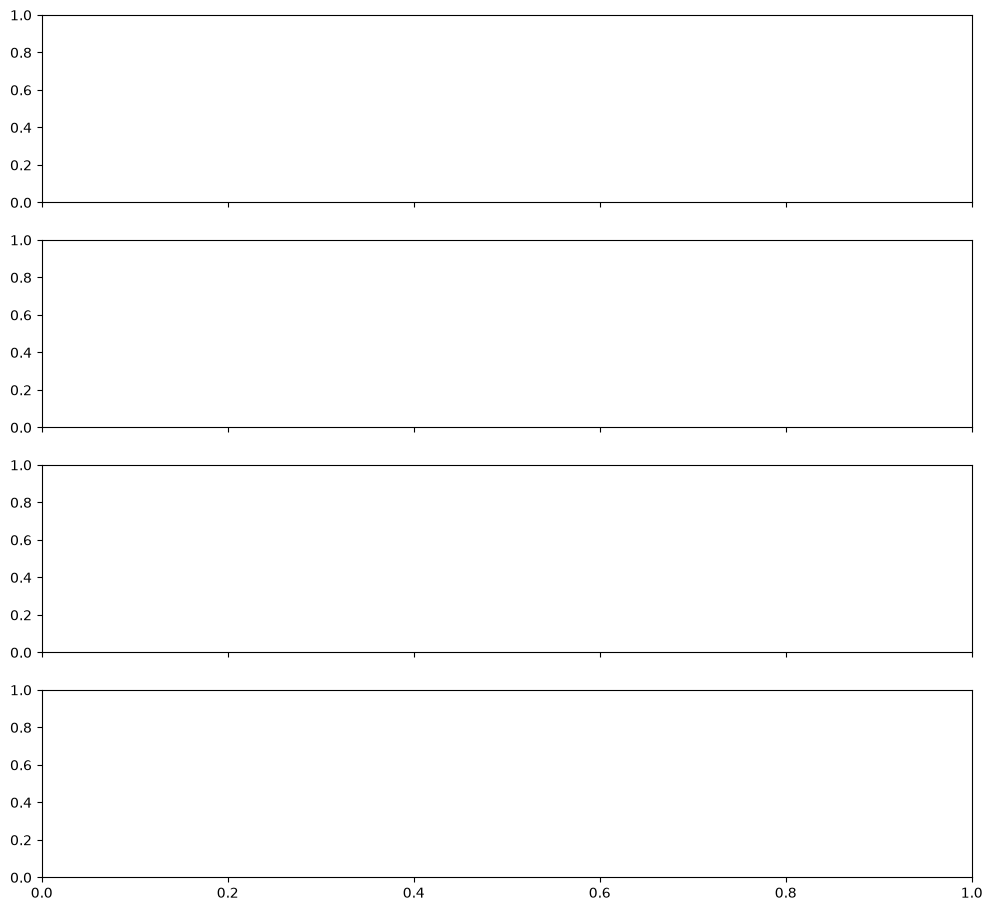

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import grangercausalitytests

# ============================================================
# Granger causality on coupled chaotic time series
# ============================================================

# Simulation settings
T = 3000
BURN_IN = 500
X0, Y0 = 0.4, 0.2
R_X, R_Y = 3.8, 3.5
MAX_LAG = 1
ALPHA = 0.05
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)


def chaotic_func(A, B, r, beta):
    """Coupled logistic-like map."""
    return A * (r - r * A - beta * B)


def generate_series(beta_xy, beta_yx, t=T, burn_in=BURN_IN):
    """
    beta_xy: effect of Y on X (Y -> X)
    beta_yx: effect of X on Y (X -> Y)
    """
    x, y = X0, Y0
    xs, ys = [], []

    for _ in range(t + burn_in):
        x_next = chaotic_func(x, y, R_X, beta_xy)
        y_next = chaotic_func(y, x, R_Y, beta_yx)
        x, y = x_next, y_next

        if not (np.isfinite(x) and np.isfinite(y)):
            raise ValueError(
                "The simulation became non-finite. Check the parameters."
            )

        if _ >= burn_in:
            xs.append(x)
            ys.append(y)

    return np.asarray(xs), np.asarray(ys)


def granger_direction(target, source, max_lag=MAX_LAG):
    """
    Test whether 'source' Granger-causes 'target'.

    statsmodels expects columns [target, source]:
    the null hypothesis is that lagged source values do not
    improve prediction of target beyond its own lagged values.
    """
    target = np.asarray(target, dtype=float).ravel()
    source = np.asarray(source, dtype=float).ravel()

    if len(target) != len(source):
        raise ValueError("Target and source must have the same length.")

    if len(target) <= max_lag + 5:
        raise ValueError("Time series is too short for the requested lag.")

    if not (np.all(np.isfinite(target)) and np.all(np.isfinite(source))):
        raise ValueError("Time series contains NaN or infinite values.")

    target_var = np.var(target)
    source_var = np.var(source)

    if target_var < 1e-14 or source_var < 1e-14:
        return {
            "p_ssr": np.nan,
            "p_params": np.nan,
            "F_ssr": np.nan,
            "F_params": np.nan,
            "target_var": target_var,
            "source_var": source_var,
            "corr": np.corrcoef(target, source)[0, 1],
            "status": "Near-constant series; test not reliable",
        }

    df = pd.DataFrame({"target": target, "source": source})

    # statsmodels may print a deprecation warning for verbose;
   
    result = grangercausalitytests(
        df[["target", "source"]],
        maxlag=[max_lag],
    )

    test_results = result[max_lag][0]
    p_ssr = float(test_results["ssr_ftest"][1])
    p_params = float(test_results["params_ftest"][1])

    return {
        "p_ssr": p_ssr,
        "p_params": p_params,
        "F_ssr": float(test_results["ssr_ftest"][0]),
        "F_params": float(test_results["params_ftest"][0]),
        "target_var": target_var,
        "source_var": source_var,
        "corr": float(np.corrcoef(target, source)[0, 1]),
        "status": "OK",
    }


# Four conditions:
# beta_xy is Y -> X; beta_yx is X -> Y.
conditions = {
    "No coupling": (0.0, 0.0),
    "Only X -> Y": (0.0, 0.10),
    "Only Y -> X": (0.02, 0.0),
    "Bidirectional": (0.02, 0.10),
}

all_results = []
series_by_condition = {}

for condition, (beta_xy, beta_yx) in conditions.items():
    X, Y = generate_series(beta_xy, beta_yx)
    series_by_condition[condition] = (X, Y)

    # Direction 1: Y -> X
    res_y_to_x = granger_direction(target=X, source=Y)

    # Direction 2: X -> Y
    res_x_to_y = granger_direction(target=Y, source=X)

    for direction, res, expected in [
        ("Y -> X", res_y_to_x, beta_xy != 0),
        ("X -> Y", res_x_to_y, beta_yx != 0),
    ]:
        all_results.append({
            "Condition": condition,
            "Direction tested": direction,
            "Direct coupling present": expected,
            "SSR F": res["F_ssr"],
            "SSR p": res["p_ssr"],
            "Parameter F": res["F_params"],
            "Parameter p": res["p_params"],
            "Target variance": res["target_var"],
            "Source variance": res["source_var"],
            "Correlation": res["corr"],
            "Status": res["status"],
        })

results_df = pd.DataFrame(all_results)

# Display results
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 6)

print("\n=== Granger-causality results ===")
print(f"Time points per series: {T}")
print(f"Burn-in discarded: {BURN_IN}")
print(f"Maximum lag: {MAX_LAG}")
print(f"Significance threshold: {ALPHA}\n")
print(results_df.to_string(index=False))

# Highlight disagreement between the two F tests
valid = results_df["Status"].eq("OK")
disagree = valid & (
    (results_df["SSR p"] < ALPHA) !=
    (results_df["Parameter p"] < ALPHA)
)

if disagree.any():
    print("\nWARNING: SSR F-test and parameter F-test disagree on significance.")
    print("Investigate numerical conditioning and regression diagnostics before")
    print("interpreting these p-values.")
    print(results_df.loc[
        disagree,
        ["Condition", "Direction tested", "SSR p", "Parameter p"]
    ].to_string(index=False))
else:
    print("\nSSR F-test and parameter F-test agree on significance for all valid tests.")

# Plot time series for each condition
fig, axes = plt.subplots(
    len(conditions), 1,
    figsize=(12, 2.8 * len(conditions)),
    sharex=True
)

ALPHA = 0.05
nodes = ["X", "Y"]

for condition in results_df["Condition"].unique():
    subset = results_df[results_df["Condition"] == condition]

    EC = np.zeros((2, 2), dtype=int)

    for _, row in subset.iterrows():
        if row["Direction tested"] == "X -> Y":
            source, target = "X", "Y"
        elif row["Direction tested"] == "Y -> X":
            source, target = "Y", "X"
        else:
            continue

        p_value = row["SSR p"]

        if np.isfinite(p_value) and p_value < ALPHA:
            EC[nodes.index(target), nodes.index(source)] = 1

    EC_df = pd.DataFrame(
        EC,
        index=nodes,
        columns=nodes
    )

    print(f"\n{condition} — Binary effective connectivity")
    print("Rows = targets; columns = sources")
    print(EC_df)